### Model Purpose

This notebook demonstrates the core concept of filter degradation:

1. **Particle accumulation:** Contamination builds up linearly over time
2. **Permeability decay:** Filter permeability decreases exponentially as particles accumulate
3. **Pressure drop increase:** As permeability drops, pressure drop rises according to Darcy's Law

This is the physical foundation for predictive maintenance: by monitoring pressure drop, we can predict when a filter needs replacement.

Note: Parameters are illustrative, not calibrated to real filter data.


### Imports

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

### Parameter

In [43]:
mu = 0.03 # Oil viscosity [Pa*s]
Q = 0.001 # Volume flow rate [m^3/s]
L = 0.02 # Filter thickness [m]
A = 0.05 # Filter area [m^2]
k0 = 1e-12 # Initial permeability [m^2]
alpha = 2 # Clogging coefficient [1/g]
c = 1 # Particle concentration [g/m^3]

### Model

In [44]:
def mass_accumulation(m, t):
    """Accumulated particle mass in the filter over time."""
    return c * Q # Constant particle feed

def pressure_drop(m):
    """Pressure drop according to Darcy due to decreasing permeability."""
    k = k0 * np.exp(-alpha * m) # Permeability decreases with accumulated mass
    return (mu * Q * L) / (k * A) # Darcy's law

### Simulation

In [45]:
t = np.linspace(0, 1000, 500) # Time in hours
m = odeint(mass_accumulation, 0, t).flatten() # Accumulated mass over time
delta_p = pressure_drop(m) # Pressure drop over time

### Visualization

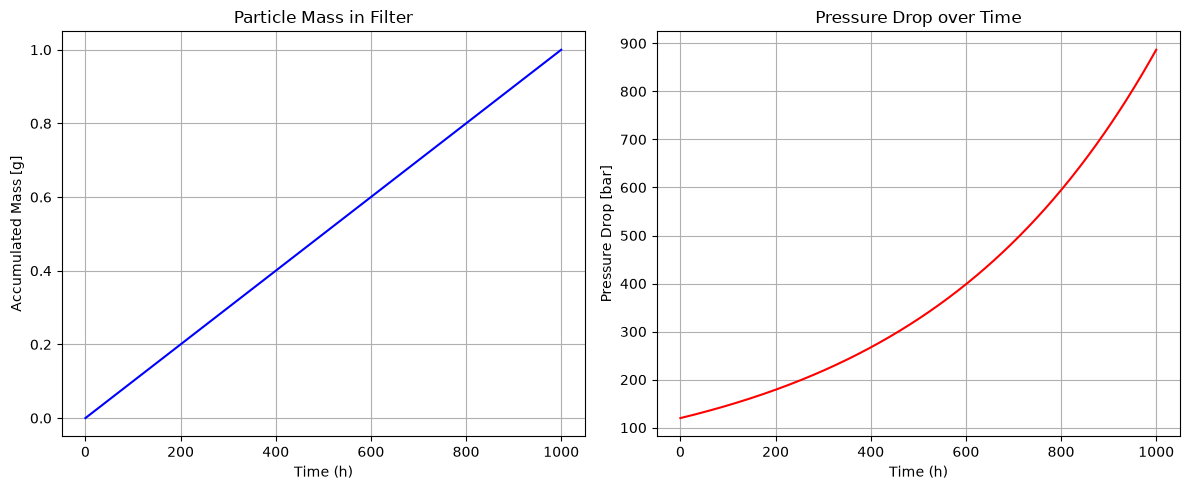

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(t, m, color='blue')
ax1.set_xlabel('Time (h)')
ax1.set_ylabel('Accumulated Mass [g]')
ax1.set_title('Particle Mass in Filter')
ax1.grid(True)

ax2.plot(t, delta_p / 1e5, color='red')
ax2.set_xlabel('Time (h)')
ax2.set_ylabel('Pressure Drop [bar]')
ax2.set_title('Pressure Drop over Time')
ax2.grid(True)

plt.tight_layout()
plt.show()